# 01 · Data collection & exploratory analysis
**Goal:** build a labelled corpus of exam questions with difficulty labels from public datasets.

No single public dataset labels question difficulty across subjects, so we combine **9 datasets**
whose structure *already encodes difficulty* (school grade, exam partition, competition level).
All datasets are downloaded **once** (`python -m src.data.download`) and stored in full under `data/raw/`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
REPORTS = ROOT / 'reports'; FIG = REPORTS / 'figures'
def show(name): display(Image(filename=str(FIG / name)))
def rj(name): return json.loads((REPORTS / name).read_text())

In [2]:
summ = json.loads((ROOT/'data/raw/datasets_summary.json').read_text())
cards = pd.DataFrame([{'dataset':k,'rows':v['total_rows'],'difficulty_signal':v['difficulty_signal'],
                       'license':v['license'],'description':v['description']} for k,v in summ.items()])
print('Total raw rows:', cards.rows.sum()); cards

Total raw rows: 244404


,dataset,rows,difficulty_signal,license,description
0,arc,7787,Easy set vs Challenge set,CC BY-SA 4.0,AI2 Reasoning Challenge: grade 3-9 science exam questions
1,sciq,13679,Easy anchor,CC BY-NC 3.0,"Crowd-sourced science exam questions (physics, chemistry, biology)"
2,openbookqa,5957,Medium anchor,Apache 2.0,Elementary science questions needing multi-step reasoning
3,commonsense_qa,12102,Easy anchor,MIT,Commonsense reasoning questions built on ConceptNet
4,race,97687,Middle school vs High school,Non-commercial research,English reading comprehension exams for Chinese students (age 12-18)
5,gsm8k,8792,Easy maths anchor,MIT,Grade-school maths word problems
6,math,12500,Level 1-5,MIT,"Competition mathematics problems (AMC, AIME, ...)"
7,mmlu,15858,elementary / high_school / college+professional subject level,MIT,57 academic subjects from elementary to professional level
8,sst2,70042,N/A (sentiment labels),Unknown/research,Stanford Sentiment Treebank (binary) - used for CO2 sentiment model


## Raw samples from every dataset

In [3]:
for name in summ:
    f = sorted((ROOT/'data/raw'/name).glob('*.parquet'))[0]
    d = pd.read_parquet(f)
    col = next(c for c in ['question','question_stem','problem','sentence'] if c in d.columns)
    print(f'--- {name} ({f.name}) ---')
    for t in d[col].head(2): print('  •', str(t)[:160].replace('\n',' '))

--- arc (ARC-Challenge_test.parquet) ---
  • An astronomer observes that a planet rotates faster after a meteorite impact. Which is the most likely effect of this increase in rotation?
  • A group of engineers wanted to know how different building designs would respond during an earthquake. They made several models of buildings and tested each for
--- sciq (test.parquet) ---
  • Compounds that are capable of accepting electrons, such as o 2 or f2, are called what?
  • What term in biotechnology means a genetically exact copy of an organism?
--- openbookqa (main_test.parquet) ---
  • A person wants to start saving money so that they can afford a nice vacation at the end of the year. After looking over their budget and expenses, they decide t
  • There is most likely going to be fog around:
--- commonsense_qa (test.parquet) ---
  • The townhouse was a hard sell for the realtor, it was right next to a high rise what?
  • There is a star at the center of what group of celestial bodies?
---

## Difficulty labelling scheme
Each source / sub-group gets a **difficulty anchor score (0-100)** based on its educational level.
The level is derived from the score: Easy < 33.3 ≤ Medium < 66.7 ≤ Hard.

In [4]:
from src.config import ANCHORS, score_to_level
pd.DataFrame([{'group':g,'anchor_score':s,'level':score_to_level(s)} for g,s in sorted(ANCHORS.items(), key=lambda x:x[1])])

,group,anchor_score,level
0,sciq,18,Easy
1,commonsense_qa,25,Easy
2,arc_easy,28,Easy
3,race_middle,28,Easy
4,gsm8k,30,Easy
5,mmlu_elementary,30,Easy
6,openbookqa,40,Medium
7,race_high,42,Medium
8,mmlu_highschool,52,Medium
9,arc_challenge,52,Medium


## Unified corpus & balanced modelling set

In [5]:
allq = pd.read_parquet(ROOT/'data/processed/all_questions.parquet')
m = pd.read_csv(ROOT/'data/processed/modelling_set.csv')
print('All cleaned & de-duplicated questions:', len(allq))
print('Balanced modelling set (≤3000 per group):', len(m))
pd.crosstab(m.split, m.level, margins=True)

All cleaned & de-duplicated questions: 144818
Balanced modelling set (≤3000 per group): 41822


level,Easy,Hard,Medium,All
split,,,,
test,1542,1162,1479,4183
train,12336,9287,11834,33457
val,1542,1160,1480,4182
All,15420,11609,14793,41822


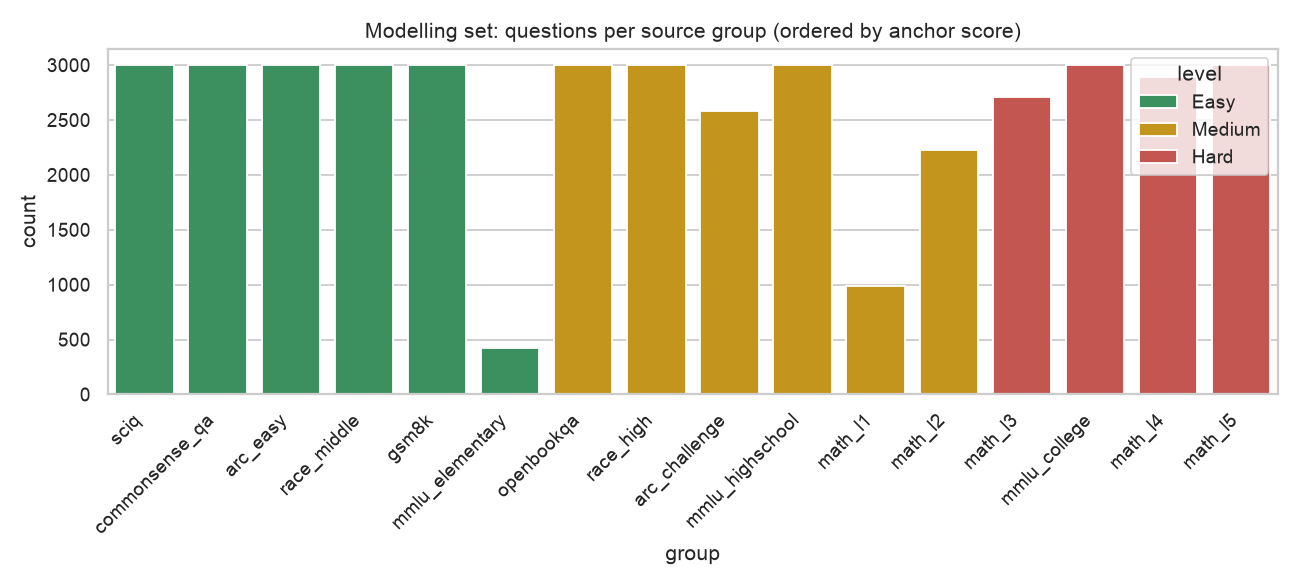

In [6]:
show('data_distribution.png')

In [7]:
m['n_words'] = m.question.str.split().str.len()
m.groupby('level').n_words.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
level,,,,,,,,
Easy,15420.0,20.1,16.5,2.0,9.0,14.0,25.0,157.0
Hard,11609.0,43.8,44.6,2.0,19.0,31.0,49.0,705.0
Medium,14793.0,24.9,43.5,1.0,9.0,13.0,24.0,589.0


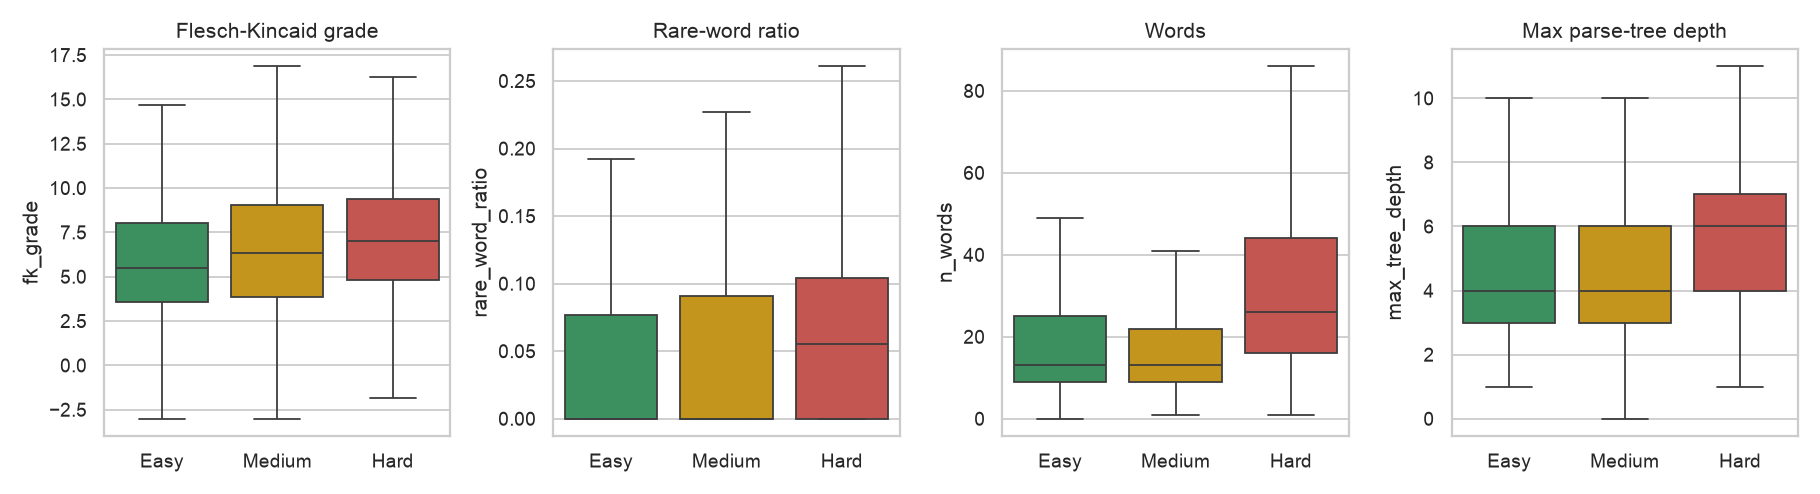

In [8]:
show('readability_by_level.png')

**Observations**
* Hard questions are clearly longer and syntactically deeper; readability grade increases with difficulty.
* Overlap between levels is large, so no single surface feature is enough → we need learned models.